# Ingest demo data into MongoDB

Reads `demo_data/bulk_upload.xlsx` (one row per product), attaches the matching image from `demo_data/Imgs/` to each row, and loads everything into `ecom_db.products` with `insert_many`.

Steps:
1. Load the Excel sheet
2. Validate + clean each row with a Pydantic `Product` model
3. Map each row's `image` column to its file and read the bytes
4. `insert_many` into MongoDB
5. Verify (counts + show an image back from the DB)

## 0. Install (only needed once)

In [14]:
import sys
!"{sys.executable}" -m ensurepip --upgrade
!"{sys.executable}" -m pip install pandas pymongo python-dotenv pydantic openpyxl

Looking in links: /var/folders/8m/3vmj9fhx65vbb71fbb4thm5h0000gn/T/tmpzgt0us0p
Processing /var/folders/8m/3vmj9fhx65vbb71fbb4thm5h0000gn/T/tmpzgt0us0p/pip-26.2.1-py3-none-any.whl
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 544.5 kB/s  0:00:21m0:00:0100:01
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 827.0 kB/s  0:00:06ta 0:00:01
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [openpyxl]3/4 [openpyxl]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip


## 1. Imports + paths

In [15]:
import os
import mimetypes
from pathlib import Path
from typing import Literal

import pandas as pd
from bson import Binary
from dotenv import load_dotenv
from pydantic import BaseModel, Field, field_validator
from pymongo import MongoClient

In [16]:
# find the project root (the folder that contains demo_data), wherever this notebook is run from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "demo_data").exists())

EXCEL_PATH = ROOT / "demo_data" / "bulk_upload.xlsx"
IMG_DIR = ROOT / "demo_data" / "Imgs"

print(EXCEL_PATH, EXCEL_PATH.exists())
print(IMG_DIR, IMG_DIR.exists())

/Users/manishthakur/Ecommerce store/demo_data/bulk_upload.xlsx True
/Users/manishthakur/Ecommerce store/demo_data/Imgs True


## 2. Load the Excel sheet

In [17]:
df = pd.read_excel(EXCEL_PATH, sheet_name="Products")

print(df.shape)
df.head()

(100, 7)


,name,description,price,category,size,color,image
0,Classic Black Tee,Soft cotton crew-neck t-shirt for everyday wear.,499,men,"S,M,L,XL",Black,classic_black_tee.jpg
1,Slim Fit Blue Jeans,Stretch denim jeans with a modern slim fit.,1499,men,"M,L,XL",Blue,slim_fit_blue_jeans.jpg
2,Navy Bomber Jacket,Lightweight bomber jacket with ribbed cuffs.,2299,men,"M,L,XL",Navy Blue,navy_bomber_jacket.jpg
3,Floral Summer Dress,"Breathable floral print dress, perfect for sum...",1799,women,"S,M,L",Pink,floral_summer_dress.jpg
4,White Cotton Kurti,Elegant embroidered kurti in pure cotton.,999,women,"S,M,L,XL",White,white_cotton_kurti.jpg


In [18]:
# same product name can appear more than once (different price / size / color) -> we keep every row as its own product
df["category"].value_counts()

category
Men      32
Women    31
Kids     27
men       4
women     4
kids      2
Name: count, dtype: int64

## 3. Product schema (Pydantic)

Cleans the raw row:
- `category` -> lowercase (`Men` and `men` become the same)
- `size` / `color` -> lists (`"S,M,L"` -> `["S", "M", "L"]`)

In [19]:
class Product(BaseModel):
    name: str = Field(min_length=1)
    description: str
    price: int = Field(gt=0)
    category: Literal["men", "women", "kids"]
    sizes: list[str]
    colors: list[str]
    image_name: str

    @field_validator("category", mode="before")
    @classmethod
    def lowercase_category(cls, value):
        return str(value).strip().lower()

    @field_validator("sizes", "colors", mode="before")
    @classmethod
    def split_comma_list(cls, value):
        if isinstance(value, str):
            return [item.strip() for item in value.split(",") if item.strip()]
        return value

## 4. Check every row has its image

In [20]:
missing = [img for img in df["image"] if not (IMG_DIR / img).exists()]

print("rows:", len(df))
print("missing images:", missing)

assert not missing, "fix the missing images before inserting"

rows: 100
missing images: []


## 5. Build the documents (row + image mapped together)

Each document stores the image bytes directly (`bson.Binary`). The images are small (< 300 KB), well under MongoDB's 16 MB document limit.

In [21]:
def load_image(filename: str) -> dict:
    path = IMG_DIR / filename
    content_type = mimetypes.guess_type(path.name)[0] or "application/octet-stream"
    return {
        "filename": filename,
        "content_type": content_type,
        "data": Binary(path.read_bytes()),
    }


documents = []
for row in df.to_dict("records"):
    product = Product(
        name=row["name"],
        description=row["description"],
        price=int(row["price"]),
        category=row["category"],
        sizes=row["size"],
        colors=row["color"],
        image_name=row["image"],
    )
    doc = product.model_dump()
    doc["image"] = load_image(product.image_name)
    documents.append(doc)

print("documents ready:", len(documents))

documents ready: 100


In [22]:
# peek at one document (without the raw bytes)
sample = {k: v for k, v in documents[0].items() if k != "image"}
sample["image"] = {k: v for k, v in documents[0]["image"].items() if k != "data"}
sample

{'name': 'Classic Black Tee',
 'description': 'Soft cotton crew-neck t-shirt for everyday wear.',
 'price': 499,
 'category': 'men',
 'sizes': ['S', 'M', 'L', 'XL'],
 'colors': ['Black'],
 'image_name': 'classic_black_tee.jpg',
 'image': {'filename': 'classic_black_tee.jpg', 'content_type': 'image/jpeg'}}

## 6. Connect to MongoDB (URI comes from `.env`)

In [24]:
load_dotenv()

client = MongoClient(os.getenv("MONGODB_URI"))
client.admin.command("ping")
print("Connected to MongoDB ✅")

db = client["ecom_db"]
collection = db["products"]

Connected to MongoDB ✅


## 7. INSERT MANY

`RESET = True` clears the collection first, so re-running this notebook doesn't create duplicates.

In [25]:
RESET = True

if RESET:
    deleted = collection.delete_many({})
    print("old products deleted:", deleted.deleted_count)

result = collection.insert_many(documents)
print("Inserted ✅", len(result.inserted_ids), "products")

old products deleted: 0
Inserted ✅ 100 products


## 8. Verify

In [26]:
print("total:", collection.count_documents({}))

for cat in ["men", "women", "kids"]:
    print(cat, "->", collection.count_documents({"category": cat}))

total: 100
men -> 36
women -> 35
kids -> 29


In [27]:
# read without the image bytes (projection) - this is how you'd list products
for p in collection.find({"category": "women", "price": {"$lt": 2000}}, {"image.data": 0}).limit(5):
    print(p["name"], "|", p["price"], "|", p["sizes"], "|", p["image"]["filename"])

Floral Summer Dress | 1799 | ['S', 'M', 'L'] | floral_summer_dress.jpg
White Cotton Kurti | 999 | ['S', 'M', 'L', 'XL'] | white_cotton_kurti.jpg
Grey Wool Cardigan | 1899 | ['S', 'M', 'L'] | grey_wool_cardigan.jpg
Casual Women T-Shirt | 650 | ['XS', 'S', 'M'] | casual_women_tshirt.jpg
Comfortable Women Dress | 1450 | ['One Size'] | comfortable_women_dress.jpg


Classic Black Tee - 499


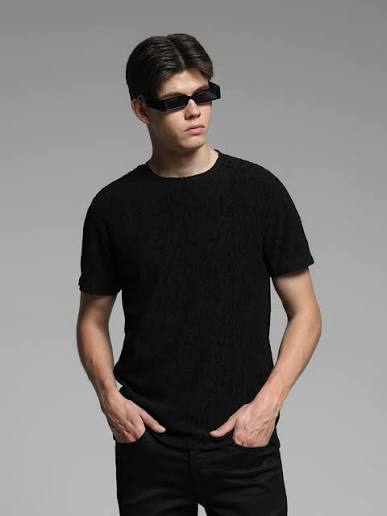

In [28]:
# pull one image back out of MongoDB and show it
from IPython.display import Image, display

p = collection.find_one({"name": "Classic Black Tee"})
print(p["name"], "-", p["price"])
display(Image(data=bytes(p["image"]["data"]), width=250))